# Tutorial

This notebook is a compact walkthrough for the proposed method, a multi-state DAG structure learning implementation for count data. It covers three paths:

- a small simulated example with ground truth, which verifies the Python API and reports structural metrics.
- a reference-delta fit, where one state is treated as the reference network and other states are learned as deltas.
- bootstrap refits, where rows are resampled within each state and replicate summaries are stored on the model.
- stability selection for penalties.
- an optional cell-level offset example, e.g. log library-size factors passed through `offsets=`.

The examples run on CPU by default and write generated files under the system temporary directory.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import torch

PROJECT_ROOT = Path.cwd().resolve()
os.chdir(PROJECT_ROOT)

C:\Users\nsato\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\nsato\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (


## 1. Network inference

In [2]:
from bbd_dagma_nb import (
    MultiStateBackboneDAGMA_NB,
    edge_metrics,
    edge_score_metrics,
    generate_multistate_nb,
    is_dag_from_weight,
    numpy_to_torch_states,
)

SEED = 21
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cpu"

## Generate multi state NB count data
sim_data, true_W_states = generate_multistate_nb(
    d=6,
    n_states=2,
    n_per_state=80,
    edge_prob=0.35,
    delta_edges=2,
    seed=SEED,
)

X_torch = numpy_to_torch_states(sim_data.X_states, device=device)
model = MultiStateBackboneDAGMA_NB(d=6, n_states=2, device=device).to(device)
model.fit(
    X_torch,
    max_iter=250,
    lr=3e-3,
    lam_l1=5e-3,
    lam_delta=3e-2,
    lam_group=5e-3,
    verbose=False,
)

print("Done.")
W_backbone = model.W0.detach().cpu().numpy()
W_states = [model.W_state(k).detach().cpu().numpy() for k in range(2)]
print("True backbone edge count:", int(sim_data.B_backbone.sum()))
print("True state edge counts:", [int(B.sum()) for B in sim_data.B_states])

Done.
True backbone edge count: 5
True state edge counts: [7, 5]


## 2. Evaluate the inferred networks

In [3]:
THRESH = 0.3
rows = []

backbone_row = {"target": "backbone", **edge_metrics(sim_data.B_backbone, W_backbone, thresh=THRESH)}
backbone_row.update(edge_score_metrics(sim_data.B_backbone, W_backbone))
backbone_row["is_dag"] = is_dag_from_weight(W_backbone, thresh=THRESH)
rows.append(backbone_row)

for k, W in enumerate(W_states):
    row = {"target": f"state{k}", **edge_metrics(sim_data.B_states[k], W, thresh=THRESH)}
    row.update(edge_score_metrics(sim_data.B_states[k], W))
    row["is_dag"] = is_dag_from_weight(W, thresh=THRESH)
    rows.append(row)

metrics_df = pd.DataFrame(rows)
display(
    metrics_df[
        ["target", "tp", "fp", "fn", "precision", "recall", "f1", "auprc", "shd", "is_dag"]
    ].round(3)
)

,target,tp,fp,fn,precision,recall,f1,auprc,shd,is_dag
0,backbone,2.0,1.0,3.0,0.667,0.400,0.500,0.668,4.0,True
1,state0,4.0,0.0,3.0,1.000,0.571,0.727,0.867,3.0,True
2,state1,4.0,0.0,1.0,1.000,0.800,0.889,1.000,1.0,True


## 3. Reference-delta fit and evaluation

`fit_reference_delta()` treats `W0` as the selected reference-state network and keeps `Delta[ref_idx]` fixed at zero. The table below uses the same structural metrics as the backbone evaluation: the reference row compares `W0` against the true reference-state graph, and each non-reference row compares `W_state(k)` against that state's true graph.

In [4]:
REF_IDX = 0

model_reference_delta = MultiStateBackboneDAGMA_NB(d=6, n_states=2, device=device).to(device)
model_reference_delta.fit_reference_delta(
    X_torch,
    ref_idx=REF_IDX,
    max_iter=250,
    lr=3e-3,
    lam_l1=5e-3,
    lam_delta=3e-2,
    lam_group=5e-3,
    verbose=False,
)

W_reference = model_reference_delta.W0.detach().cpu().numpy()
W_states_reference_delta = [
    model_reference_delta.W_state(k).detach().cpu().numpy() for k in range(2)
]

rows_reference_delta = []
reference_row = {
    "target": f"reference_state{REF_IDX}",
    **edge_metrics(sim_data.B_states[REF_IDX], W_reference, thresh=THRESH),
}
reference_row.update(edge_score_metrics(sim_data.B_states[REF_IDX], W_reference))
reference_row["is_dag"] = is_dag_from_weight(W_reference, thresh=THRESH)
rows_reference_delta.append(reference_row)

for k, W in enumerate(W_states_reference_delta):
    if k == REF_IDX:
        continue
    row = {"target": f"state{k}_vs_ref{REF_IDX}", **edge_metrics(sim_data.B_states[k], W, thresh=THRESH)}
    row.update(edge_score_metrics(sim_data.B_states[k], W))
    row["is_dag"] = is_dag_from_weight(W, thresh=THRESH)
    rows_reference_delta.append(row)

reference_delta_metrics_df = pd.DataFrame(rows_reference_delta)
display(
    reference_delta_metrics_df[
        ["target", "tp", "fp", "fn", "precision", "recall", "f1", "auprc", "shd", "is_dag"]
    ].round(3)
)

,target,tp,fp,fn,precision,recall,f1,auprc,shd,is_dag
0,reference_state0,4.0,0.0,3.0,1.0,0.571,0.727,0.896,3.0,True
1,state1_vs_ref0,3.0,0.0,2.0,1.0,0.600,0.750,1.000,2.0,True


## 4. Bootstrap refits

Passing `boot=True` resamples rows within each state with replacement before each refit. With `n_boot > 1`, raw replicate arrays and summaries are stored in `model.bootstrap_`. If `offsets=` is passed, offsets are resampled with the same row indices.


In [5]:
# Keep n_boot small here for tutorial runtime; increase it for real analyses.
model_boot = MultiStateBackboneDAGMA_NB(d=6, n_states=2, device=device).to(device)
model_boot.fit(
    X_torch,
    boot=True,
    n_boot=3,
    boot_seed=SEED,
    boot_edge_thresh=THRESH,
    max_iter=150,
    lr=3e-3,
    lam_l1=5e-3,
    lam_delta=3e-2,
    lam_group=5e-3,
    verbose=False,
)

boot = model_boot.bootstrap_
print("Bootstrap replicates:", boot["n_boot"])
print("W0 bootstrap shape:", boot["W0"].shape)
print("State mean shape:", boot["W_states_mean"].shape)

W_states_boot_mean = [boot["W_states_mean"][k] for k in range(2)]
W_states_boot_mean

Bootstrap replicates: 3
W0 bootstrap shape: (3, 6, 6)
State mean shape: (2, 6, 6)


[array([[ 0.        , -0.12862836,  0.23210786,  0.08322572,  0.16223377,
         -0.5790406 ],
        [-0.05949866,  0.        , -0.71679735,  0.08033093,  0.6333778 ,
         -0.04295119],
        [ 0.1722445 , -0.193906  ,  0.        , -0.19712539,  0.39499202,
         -0.00751753],
        [ 0.07867927,  0.14544149, -0.1605859 ,  0.        ,  0.10171481,
         -0.03250992],
        [-0.01179413,  0.05578762,  0.07405379,  0.01759714,  0.        ,
          0.01021572],
        [-0.15034224,  0.01217964,  0.06402136,  0.02646735,  0.15234369,
          0.        ]], dtype=float32),
 array([[ 0.0000000e+00, -3.1748280e-01, -3.5245743e-01, -3.1632159e-02,
          9.2841424e-02, -5.4928744e-01],
        [-5.5514067e-02,  0.0000000e+00,  1.6584972e-02,  1.3028572e-01,
          1.6037624e-04,  8.4871864e-03],
        [-2.8438747e-01,  3.5240572e-02,  0.0000000e+00, -1.6372482e-01,
         -2.3341745e-01,  8.6966418e-02],
        [ 6.9391251e-02,  6.0590011e-01, -1.1890515e-01,

## 5. Stability selection for penalty tuning


In [6]:
import stability_selection as ss

stability_result = ss.run_stability_selection(
    X_torch,
    grids=[
        (0.002, 0.01),
        (0.002, 0.03)
    ],
    n_refits=5
)
stability_summary_df = stability_result["summary_df"]

[combo 1/2 refit 1/5] lam_ref=0.002 lam_delta=0.01 val_ll=-7.921503
[combo 1/2 refit 2/5] lam_ref=0.002 lam_delta=0.01 val_ll=-8.558916
[combo 1/2 refit 3/5] lam_ref=0.002 lam_delta=0.01 val_ll=-7.749918
[combo 1/2 refit 4/5] lam_ref=0.002 lam_delta=0.01 val_ll=-7.510112
[combo 1/2 refit 5/5] lam_ref=0.002 lam_delta=0.01 val_ll=-7.396867
[combo 2/2 refit 1/5] lam_ref=0.002 lam_delta=0.03 val_ll=-7.908643
[combo 2/2 refit 2/5] lam_ref=0.002 lam_delta=0.03 val_ll=-8.484974
[combo 2/2 refit 3/5] lam_ref=0.002 lam_delta=0.03 val_ll=-7.766078
[combo 2/2 refit 4/5] lam_ref=0.002 lam_delta=0.03 val_ll=-7.560367
[combo 2/2 refit 5/5] lam_ref=0.002 lam_delta=0.03 val_ll=-7.371117


In [7]:
display(
    stability_summary_df[
        [
            "combo_id",
            "lam_ref",
            "lam_delta",
            "validation_ll_mean",
            "validation_ll_se",
            "instability",
            "selected",
        ]
    ].round(4).head()
)

stability_result["selected_penalty"]


,combo_id,lam_ref,lam_delta,validation_ll_mean,validation_ll_se,instability,selected
0,0,0.002,0.01,-7.8275,0.2045,0.0853,False
1,1,0.002,0.03,-7.8182,0.1900,0.0373,True


{'combo_id': 1,
 'lam_ref': 0.002,
 'lam_delta': 0.03,
 'n_refits': 5,
 'validation_ll_mean': -7.818236017227173,
 'validation_ll_sd': 0.4248076280778804,
 'validation_ll_se': 0.18997974674851778,
 'instability': 0.03733333200216293,
 'mean_selected_delta_edges_per_refit': 3.4,
 'combo_sec': 34.3115538,
 'lambda_ref_selected': True,
 'instability_eligible': True,
 'selected_by_fallback': False,
 'selected': True}

## 6. Inspect Estimated Adjacency Matrices

`W_state(k)` returns a weighted adjacency matrix for state `k`. Most downstream workflows convert it to a binary adjacency matrix with `abs(W) > threshold` and zero diagonal.

In [8]:
Adj_states = []
gene_labels = [f"g{i}" for i in range(W_states[0].shape[0])]

for k, W in enumerate(W_states):
    A = (np.abs(W) > THRESH).astype(int)
    np.fill_diagonal(A, 0)
    Adj_states.append(A)


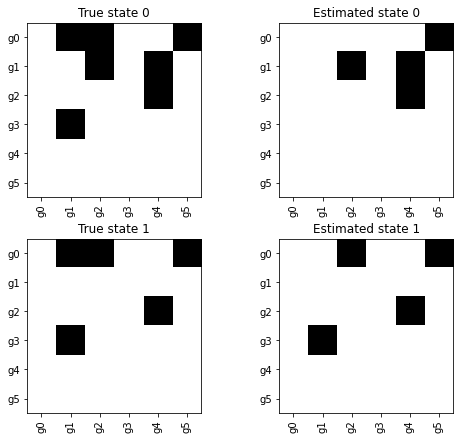

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(7, 6), constrained_layout=True)
for k in range(2):
    axes[k, 0].imshow(sim_data.B_states[k], cmap="Greys", vmin=0, vmax=1)
    axes[k, 0].set_title(f"True state {k}")
    axes[k, 1].imshow(Adj_states[k], cmap="Greys", vmin=0, vmax=1)
    axes[k, 1].set_title(f"Estimated state {k}")
    for ax in axes[k]:
        ax.set_xticks(range(6))
        ax.set_yticks(range(6))
        ax.set_xticklabels(gene_labels, rotation=90)
        ax.set_yticklabels(gene_labels)

## 7. Optional: sample-level offsets

`MultiStateBackboneDAGMA_NB.fit()` accepts `offsets`, a list with one tensor per state. Each tensor must have length equal to the number of cells/samples in that state. Internally the offset is added to the linear predictor for every gene in that cell: `eta = alpha + X @ W + offset`.

A common use is library-size normalization for count data. If `size_factor_i` is the per-cell exposure or library-size factor, pass `log(size_factor_i)`. Centering the log offset is usually convenient because the model also has intercept terms (`alpha`).

In [10]:
# Example: build centered log-library-size offsets from the current simulated counts.
# If you already have size factors, replace this block with np.log(size_factors).
offsets_np = []
for X in sim_data.X_states:
    library_size = X.sum(axis=1) + 1.0
    log_offset = np.log(library_size) - np.log(np.median(library_size))
    offsets_np.append(log_offset.astype(np.float32))

offsets = [torch.tensor(o, dtype=torch.float32, device=device) for o in offsets_np]
print("Offset shapes:", [tuple(o.shape) for o in offsets])

model_with_offset = MultiStateBackboneDAGMA_NB(d=6, n_states=2, device=device).to(device)
model_with_offset.fit(
    X_torch,
    offsets=offsets,
    max_iter=250,
    lr=3e-3,
    lam_l1=5e-3,
    lam_delta=3e-2,
    lam_group=5e-3,
    verbose=False,
)

W_states_offset = [model_with_offset.W_state(k).detach().cpu().numpy() for k in range(2)]
rows_offset = []
for k, W in enumerate(W_states_offset):
    row = {"target": f"state{k}", **edge_metrics(sim_data.B_states[k], W, thresh=THRESH)}
    row.update(edge_score_metrics(sim_data.B_states[k], W))
    row["is_dag"] = is_dag_from_weight(W, thresh=THRESH)
    rows_offset.append(row)

pd.DataFrame(rows_offset)[
    ["target", "tp", "fp", "fn", "precision", "recall", "f1", "auprc", "shd", "is_dag"]
].round(3)


Offset shapes: [(80,), (80,)]


,target,tp,fp,fn,precision,recall,f1,auprc,shd,is_dag
0,state0,3.0,0.0,4.0,1.0,0.429,0.600,0.773,4.0,True
1,state1,2.0,0.0,3.0,1.0,0.400,0.571,0.943,3.0,True
